## **Bank Nifty Predictability Under Regulatory Expiry-Structure Reform**

### **Notebook 09: Figures for Publication**

[![Seaborn](https://img.shields.io/badge/Seaborn-Latest-blue)](https://seaborn.pydata.org/)

---

**Scope:** Generate high-resolution, publication-quality figures (300 DPI, serif font styling) for inclusion in the final research manuscript.

---


### **Pipeline Context**

This is a sequential 9-notebook experimental workflow:

1. **01_data_collection.ipynb**
2. **02_data_cleaning_eda.ipynb**
3. **03_feature_engineering.ipynb**
4. **04_volatility_regime_detection.ipynb**
5. **05_baseline_models.ipynb**
6. **06_proposed_model.ipynb**
7. **07_ablation_study.ipynb**
8. **08_evaluation_and_diagnostics.ipynb**
9. **09_figures_for_paper.ipynb**

---
**Current Location:** 9. **09_figures_for_paper.ipynb** <- *You are here*

---


## 1. Introduction

### 1.1 Purpose of This Notebook
This notebook uses our styling module `src.plotting` to produce publication-ready figures. We plot:
1. **Volatility Regimes on Price History**: Highlighting HMM-derived market regimes over time.
2. **Feature Importance Chart**: Horizontal bar chart showing importances of technical vs derivatives features.
3. **Forecast Error Distributions**: Overlaid density functions of baseline vs proposed model errors.

## 2. Environment Setup

In [1]:
import sys
from pathlib import Path
import pandas as pd
import joblib
import matplotlib.pyplot as plt

project_dir = Path("e:/BN_Structure_Reforms/banknifty-expiry-volatility-ml")
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src import config
from src.plotting import set_style, plot_regimes, plot_feature_importance, plot_error_distribution
set_style()

## 3. Data Integration

In [2]:
train = pd.read_parquet(config.PROCESSED_DATA_DIR / "train.parquet")
val = pd.read_parquet(config.PROCESSED_DATA_DIR / "val.parquet")
test = pd.read_parquet(config.PROCESSED_DATA_DIR / "test.parquet")
df_all = pd.concat([train, val, test]).sort_values('Date')

## 4. Figure 1: HMM Volatility Regimes Shading

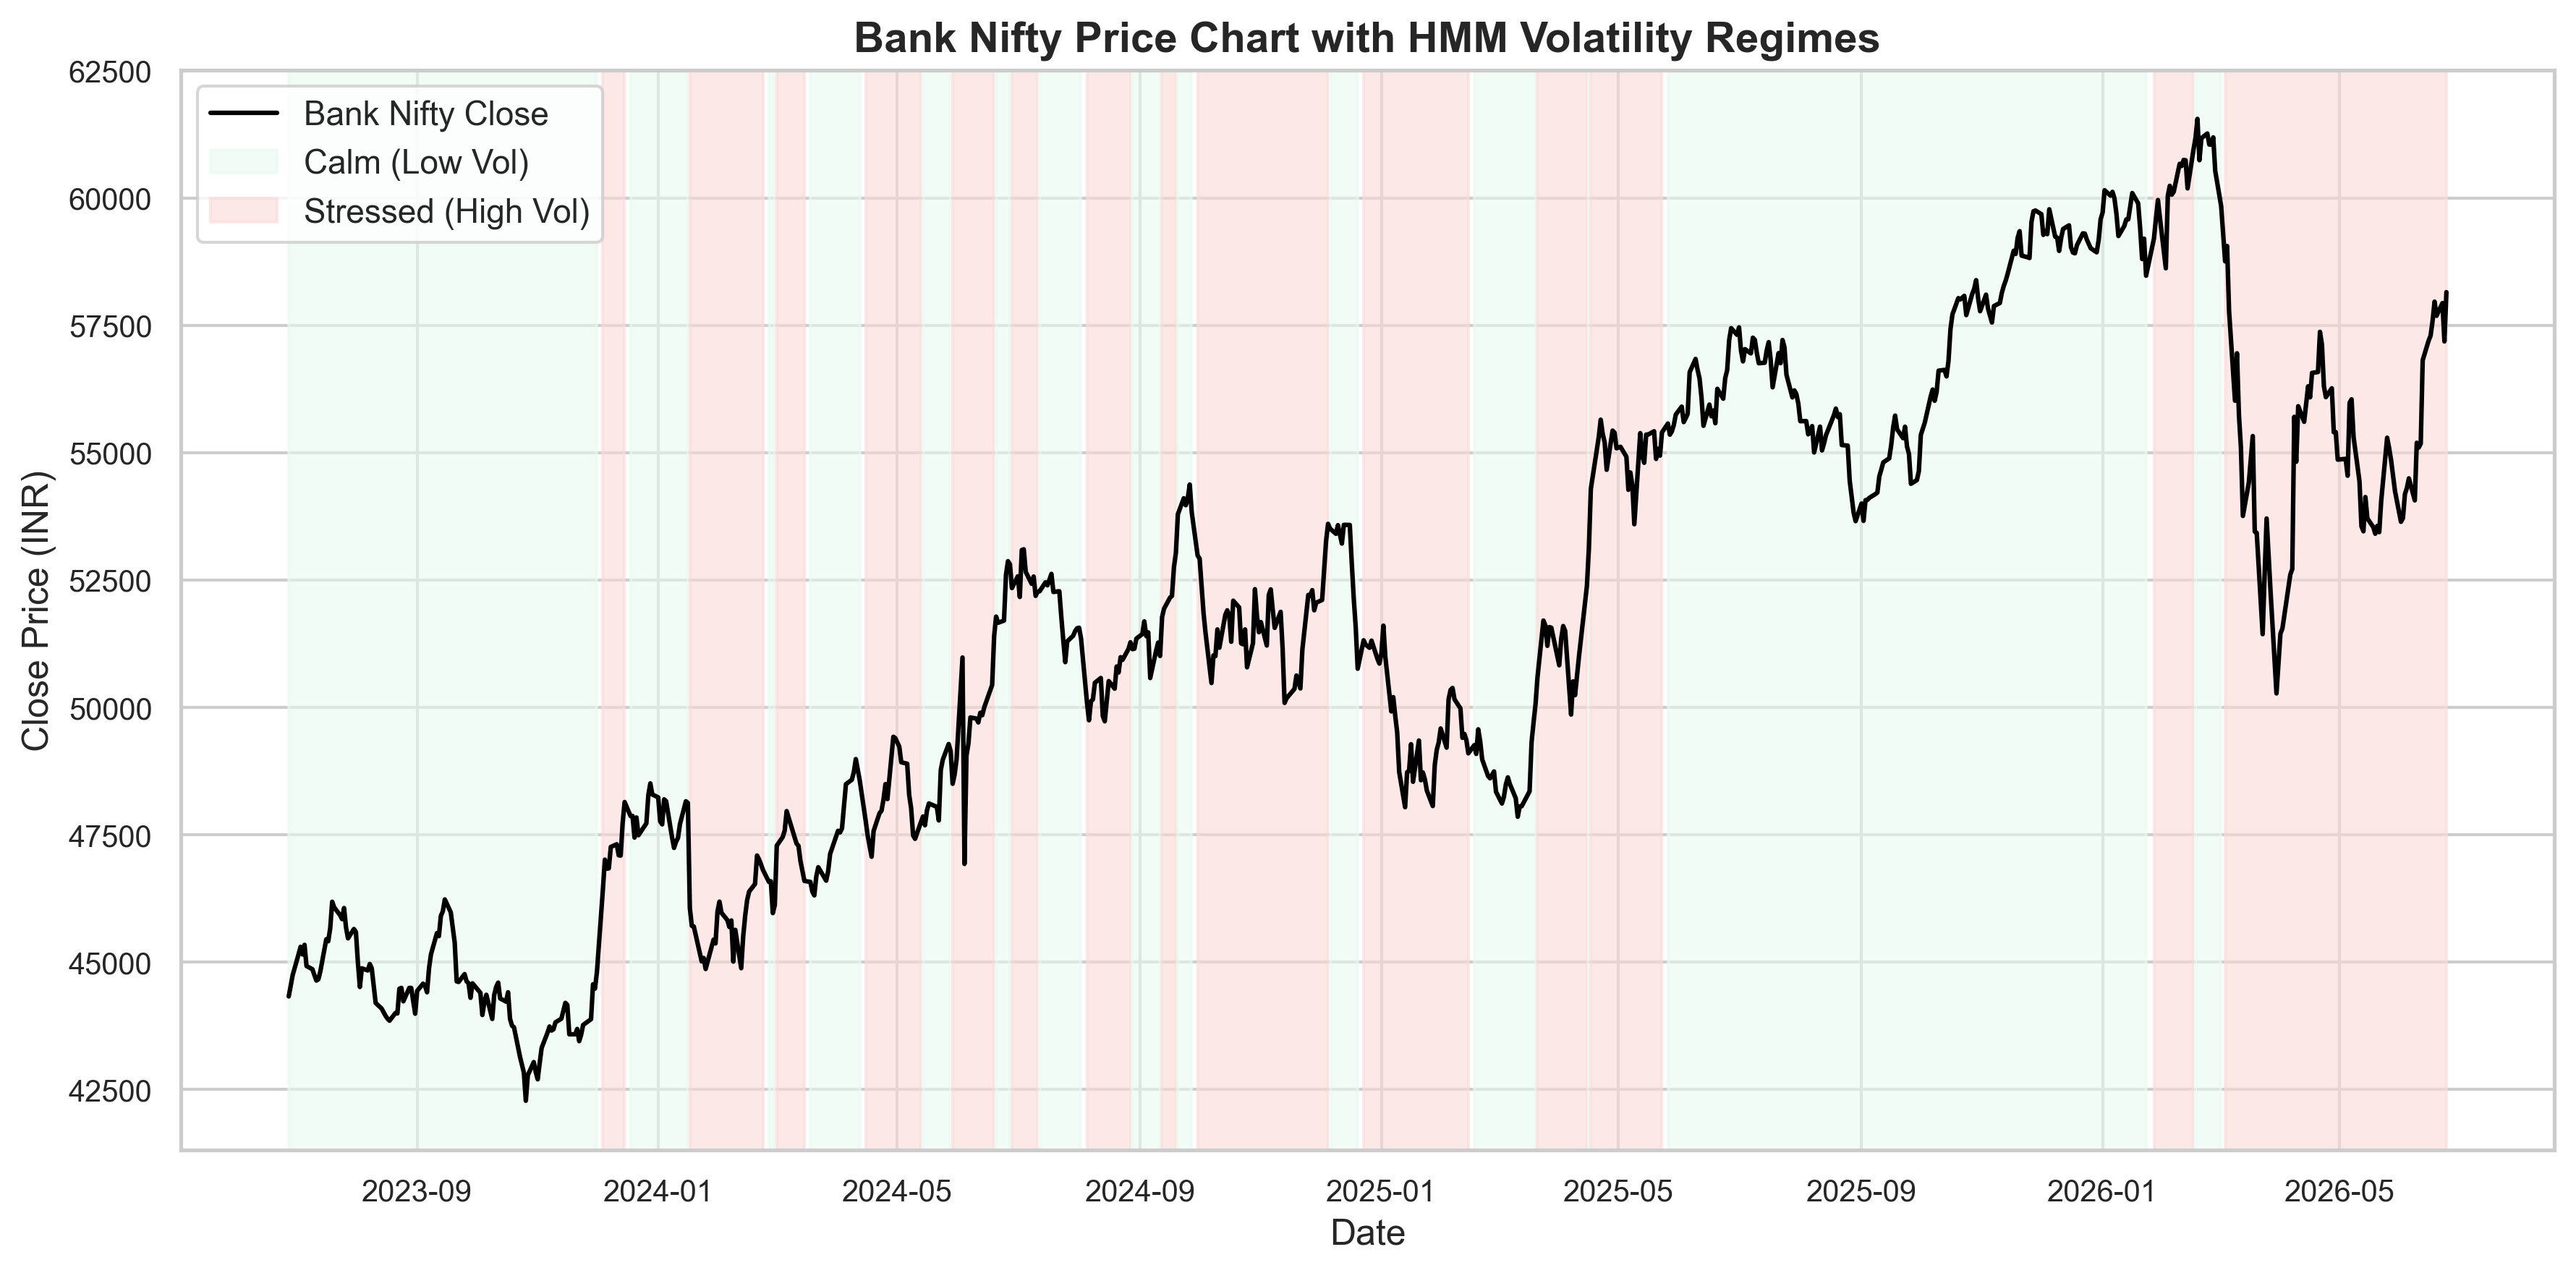

In [3]:
fig_reg = plot_regimes(df_all)
fig_reg.savefig(config.FIGURES_DIR / "banknifty_regimes.png", dpi=300)
plt.show()

## 5. Figure 2: Proposed Model Feature Importance

e:\BN_Structure_Reforms\banknifty-expiry-volatility-ml\src\plotting.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


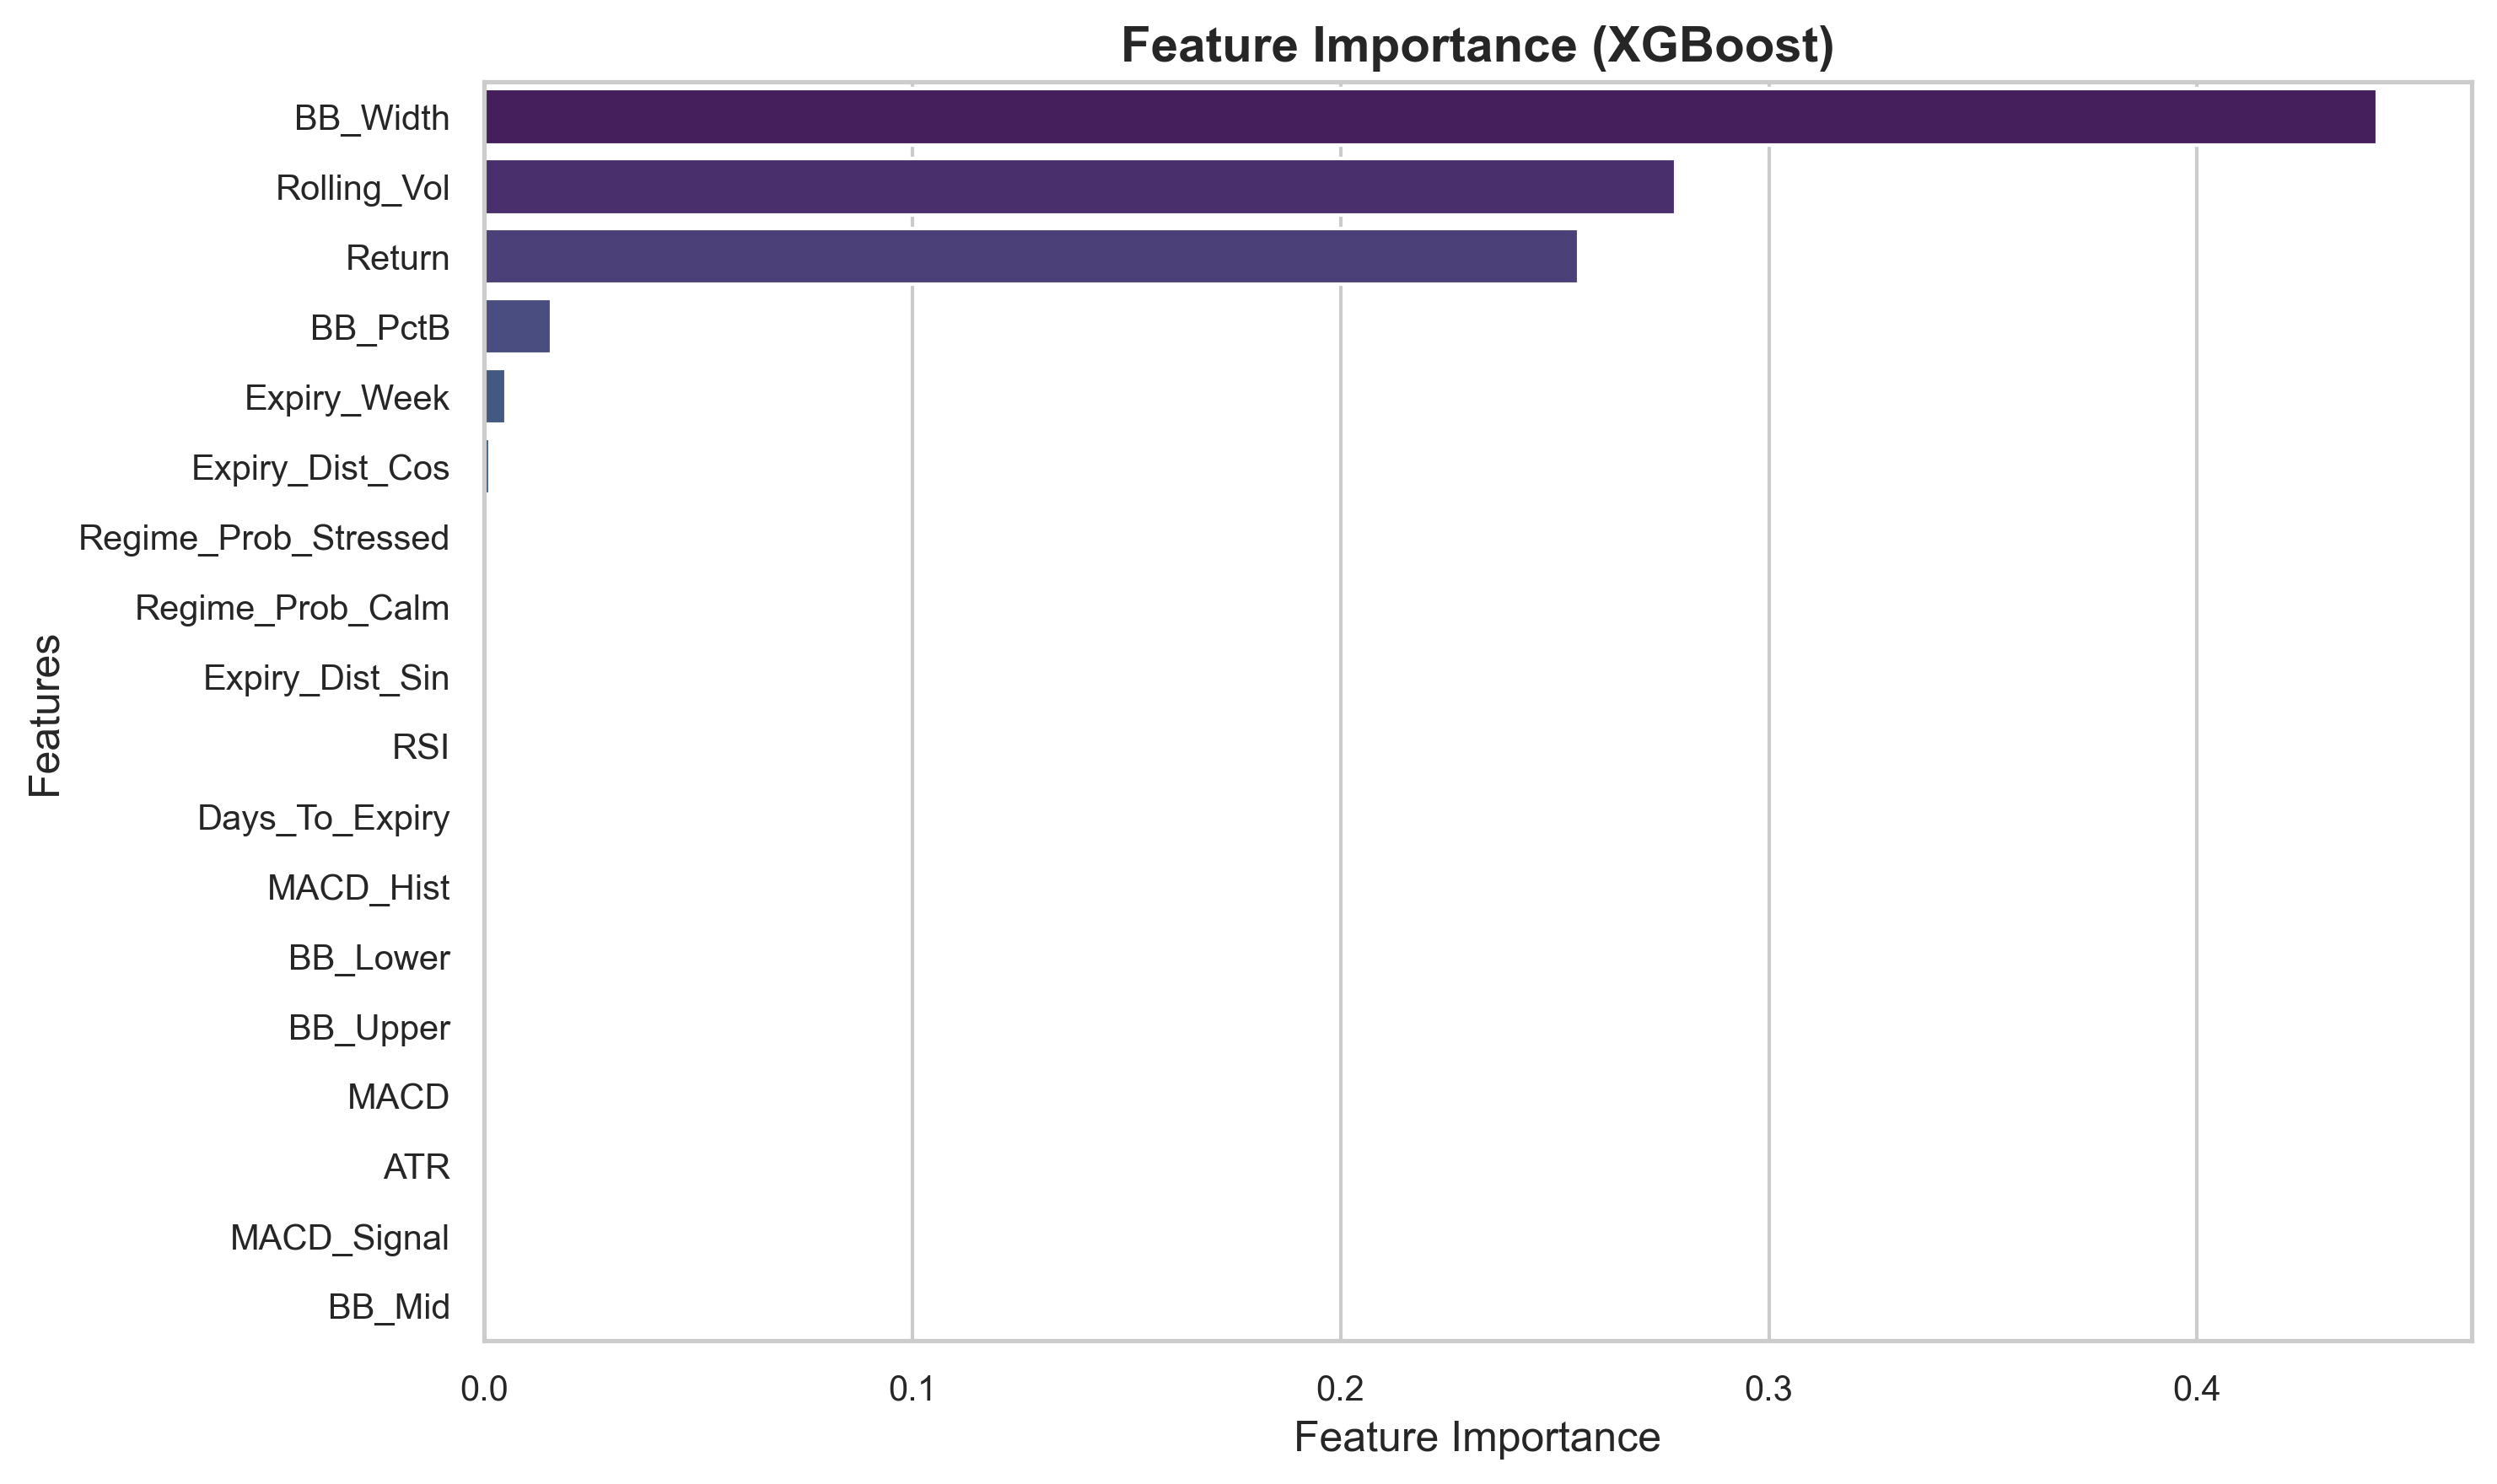

In [4]:
model = joblib.load(config.MODELS_DIR / "proposed_xgb.joblib")
proposed_features = [
    'RSI', 'MACD', 'MACD_Signal', 'MACD_Hist', 'BB_Mid', 'BB_Upper', 'BB_Lower', 'BB_PctB', 'BB_Width', 'ATR', 'Rolling_Vol', 'Return',
    'Days_To_Expiry', 'Expiry_Week', 'Expiry_Dist_Sin', 'Expiry_Dist_Cos',
    'Regime_Prob_Calm', 'Regime_Prob_Stressed'
]
imp_df = pd.DataFrame({
    'Feature': proposed_features,
    'Importance': model.feature_importances_
})
fig_imp = plot_feature_importance(imp_df)
fig_imp.savefig(config.FIGURES_DIR / "feature_importance.png", dpi=300)
plt.show()

## 6. Figure 3: Forecast Error Distributions

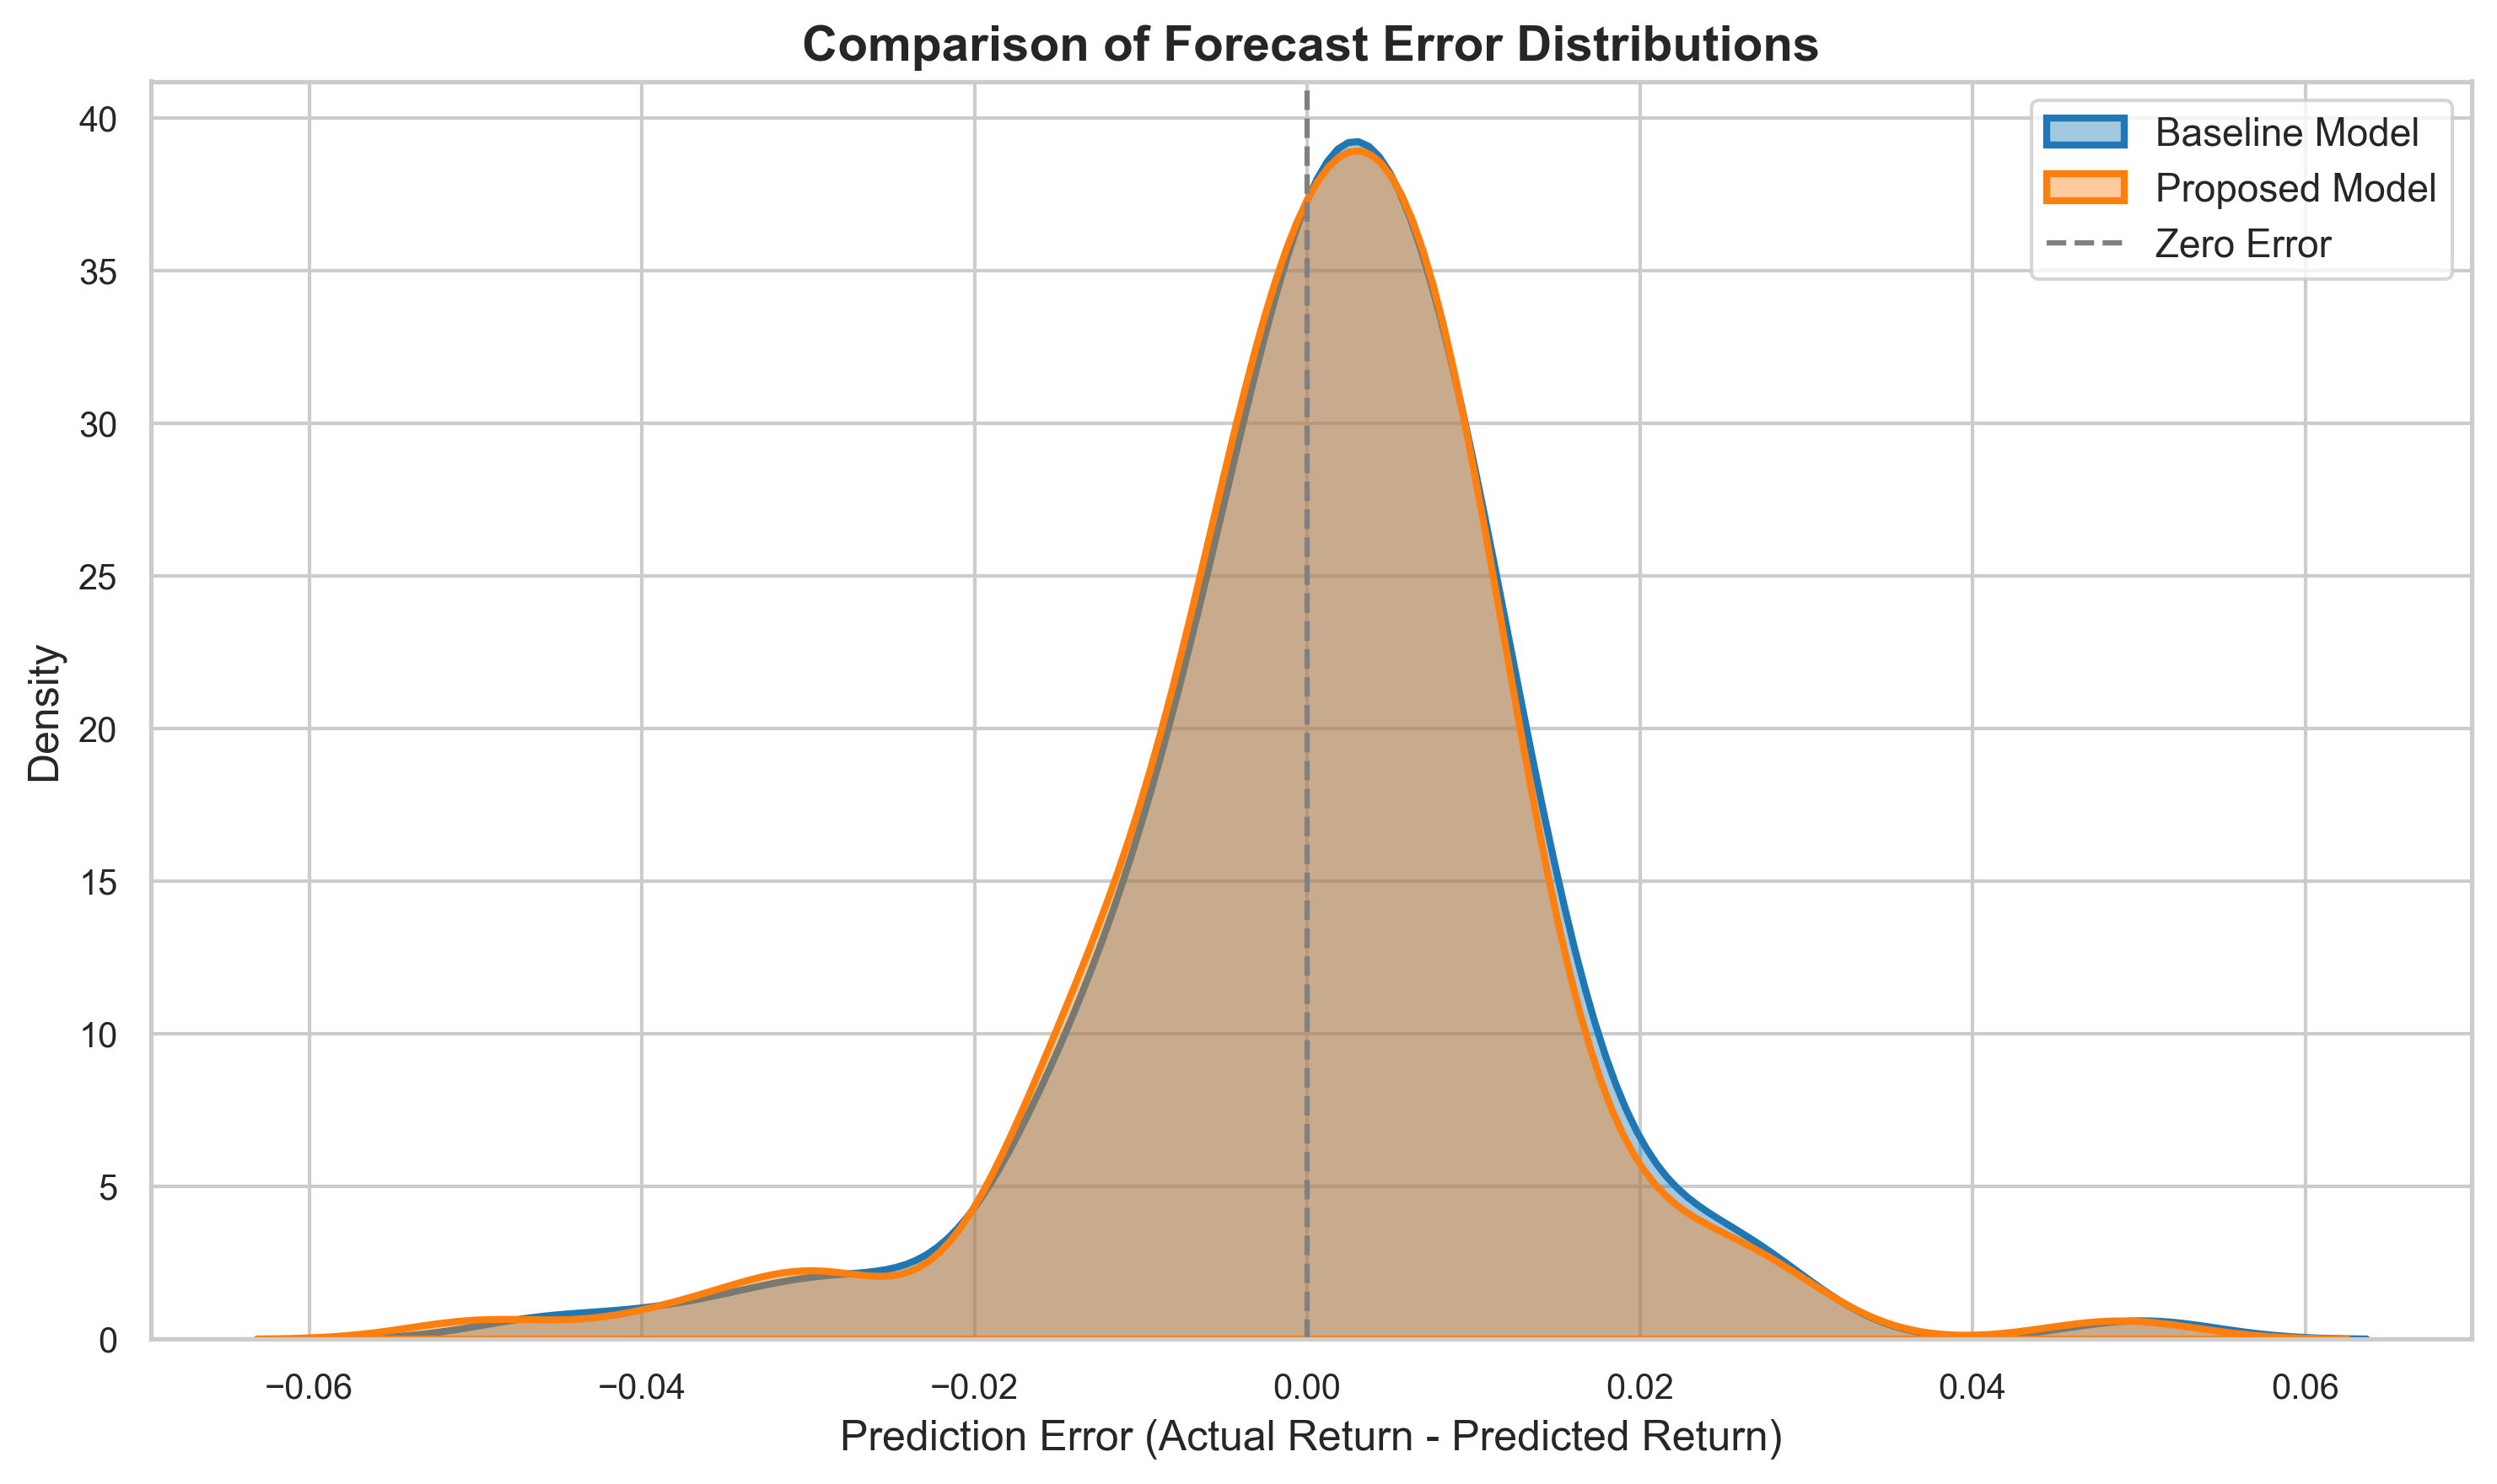

In [5]:
predictions = joblib.load(config.MODELS_DIR / "ablation_predictions.joblib")
y_test = test['Target'].values
errors = {
    "Baseline Model": y_test - predictions["Baseline (Technical Only)"],
    "Proposed Model": y_test - predictions["Proposed (Combined)"]
}
fig_err = plot_error_distribution(errors)
fig_err.savefig(config.FIGURES_DIR / "error_distribution.png", dpi=300)
plt.show()